# 1)


In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn scipy -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 2) load data
  `nhamcs_synthetic_correlated_realistic.csv` (Files -> Upload)    .

In [ ]:
df = pd.read_csv('./data/nhamcs_data_2018_22.csv')
print(df.shape)
df.head(3)

(58124, 36)


,chief_complaint_text,age,sex,ems_arrival,temp,heart_rate,resp_rate,sys_bp,dias_bp,spo2,...,hist_esrd,hist_pe,hist_hiv,hist_high_cholesterol,hist_hypertension,hist_obesity,hist_sleep_apnea,hist_osteoporosis,hist_substance_abuse,target_triage_acuity
0,"generalized weakness, new onset",12,Female,No,38.6,105,20,105,68,93,...,0,0,0,0,1,0,0,0,0,Normal
1,"mild muscle strain. chronic low back pain, stable",43,Female,No,37.0,66,18,98,59,93,...,0,1,0,0,0,1,0,0,0,Normal
2,mild cough,41,Female,No,36.8,76,17,115,86,99,...,0,0,0,0,0,0,0,0,0,Normal


# 3)  columns + Train/Test split
 data ****   (Encoding/Scaling/TF-IDF) —       Pipeline
  `fit`    training     cross-validation.

In [4]:
class_order = ['Normal', 'Urgent', 'Critical']
class_to_idx = {c: i for i, c in enumerate(class_order)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
y = df['target_triage_acuity'].map(class_to_idx).values

text_col = 'chief_complaint_text'
feature_cols = [c for c in df.columns if c != 'target_triage_acuity']
X = df[feature_cols].copy()

cat_cols = X.drop(columns=[text_col]).select_dtypes(include='object').columns.tolist()
if not cat_cols:  # pandas versions that report string columns as 'str' dtype instead of 'object'
    cat_cols = X.drop(columns=[text_col]).select_dtypes(include='str').columns.tolist()
num_cols = [c for c in feature_cols if c not in cat_cols + [text_col]]

print("Categorical (-> OneHotEncoder):", cat_cols)
print("Numeric (-> StandardScaler):", num_cols)
print("Text (-> TfidfVectorizer):", text_col)

Categorical (-> OneHotEncoder): ['sex', 'ems_arrival', 'episode', 'is_injury_poison']
Numeric (-> StandardScaler): ['age', 'temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2', 'pain_score', 'seen_last_72h', 'hist_alzheimers', 'hist_asthma', 'hist_cancer', 'hist_stroke', 'hist_ckd', 'hist_copd', 'hist_chf', 'hist_cad', 'hist_depression', 'hist_diabetes_t1', 'hist_diabetes_t2', 'hist_diabetes_unspec', 'hist_esrd', 'hist_pe', 'hist_hiv', 'hist_high_cholesterol', 'hist_hypertension', 'hist_obesity', 'hist_sleep_apnea', 'hist_osteoporosis', 'hist_substance_abuse']
Text (-> TfidfVectorizer): chief_complaint_text


C:\Users\eihaa\AppData\Local\Temp\ipykernel_25648\2477655855.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.drop(columns=[text_col]).select_dtypes(include='object').columns.tolist()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (46499, 35) | Test: (11625, 35)


# 4) ColumnTransformer
 OneHotEncoder   StandardScaler   TF-IDF   —  
   (sparse)   .

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('text', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=500,
                                  stop_words='english'), text_col),
    ],
    remainder='drop'
)

# 5)  model  Pipelines


In [7]:
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (Linear)":        SVC(kernel='linear', probability=False, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
}

pipelines = {
    name: Pipeline([('preprocess', preprocessor), ('clf', model)])
    for name, model in base_models.items()
}

# 6)    Pipeline
 Pipeline  fit_transform  training  transform   testing —    
   model (   "needs_scaling"   ).

In [8]:
results = []
trained_pipelines = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='macro')
    rec = recall_score(y_test, preds, average='macro')
    f1 = f1_score(y_test, preds, average='macro')

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')

    results.append({
        "Model": name, "Accuracy": acc, "Precision (macro)": prec,
        "Recall (macro)": rec, "F1 (macro)": f1,
        "CV Accuracy (mean)": cv_scores.mean(), "CV Accuracy (std)": cv_scores.std(),
    })
    trained_pipelines[name] = pipe
    print(f"Done: {name} -> Accuracy = {acc:.4f}")

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df

Done: Logistic Regression -> Accuracy = 0.9203
Done: Decision Tree -> Accuracy = 0.8715
Done: Random Forest -> Accuracy = 0.9200
Done: Gradient Boosting -> Accuracy = 0.9175


C:\Users\eihaa\OneDrive\Desktop\notebook\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\eihaa\OneDrive\Desktop\notebook\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\eihaa\OneDrive\Desktop\notebook\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\eihaa\OneDrive\Desktop\notebook\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The

Done: SVM (Linear) -> Accuracy = 0.9200
Done: KNN -> Accuracy = 0.7796


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),CV Accuracy (mean),CV Accuracy (std)
0,Logistic Regression,0.920258,0.921229,0.920258,0.920629,0.922816,0.001945
1,Random Forest,0.920000,0.920803,0.920000,0.920314,0.921160,0.001599
2,SVM (Linear),0.920000,0.920989,0.920000,0.920378,0.922644,0.001541
3,Gradient Boosting,0.917505,0.917634,0.917505,0.917548,0.914342,0.001808
4,Decision Tree,0.871484,0.872884,0.871484,0.871993,0.871159,0.001593
5,KNN,0.779613,0.776740,0.779613,0.777067,0.774683,0.003484


# 7) comparison   model


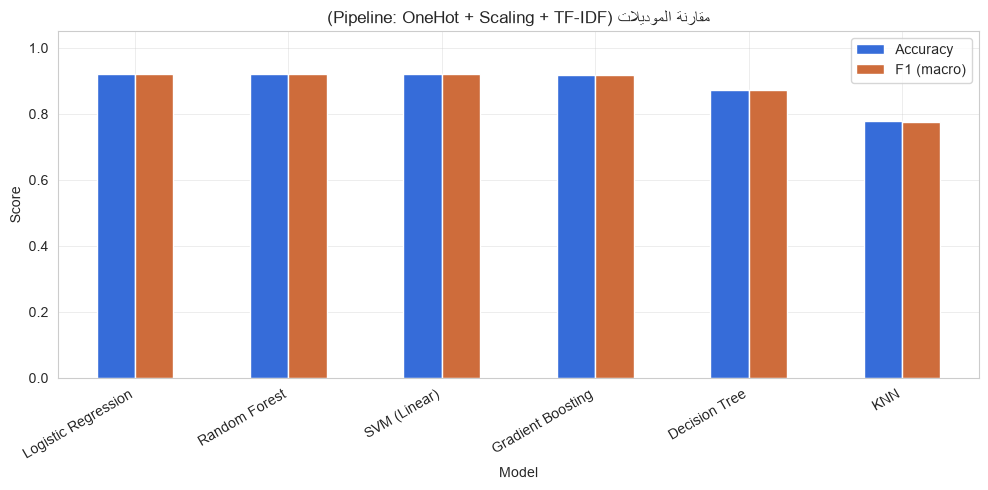

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
results_df.set_index("Model")[["Accuracy", "F1 (macro)"]].plot(kind='bar', ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("comparison model (Pipeline: OneHot + Scaling + TF-IDF)")
ax.set_ylabel("Score")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

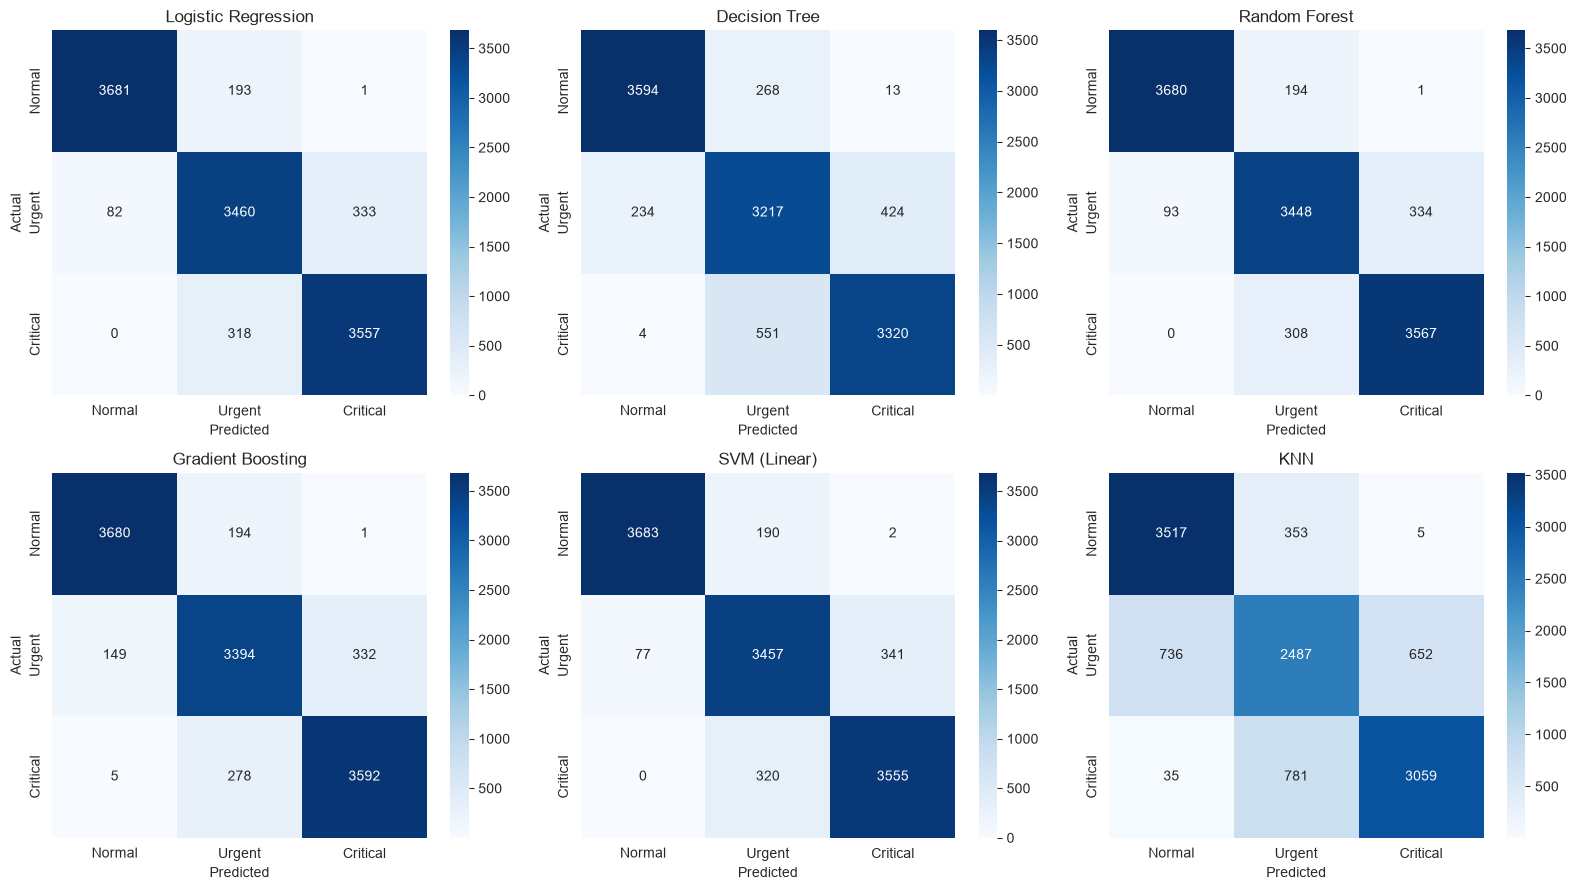

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, pipelines.keys()):
    preds = trained_pipelines[name].predict(X_test)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_order, yticklabels=class_order)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# 7.1) Confusion Matrix   (Normalized)
  Confusion Matrix   ratio     (Actual) —   ratio  
Done           .

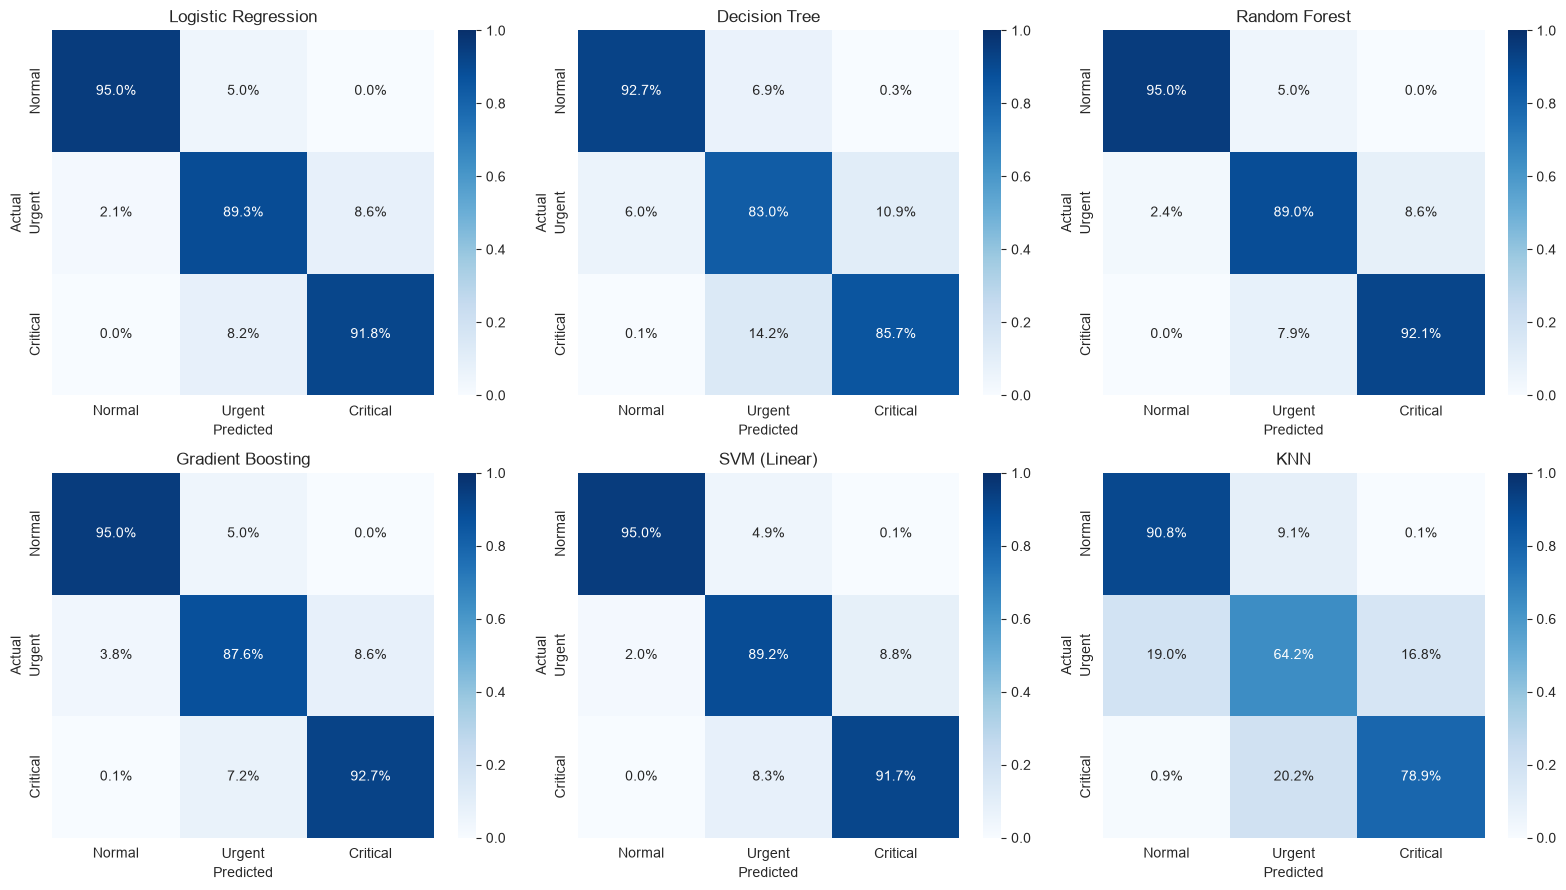

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, pipelines.keys()):
    preds = trained_pipelines[name].predict(X_test)
    cm = confusion_matrix(y_test, preds, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.1%', cmap='Blues', ax=ax, vmin=0, vmax=1,
                xticklabels=class_order, yticklabels=class_order)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# 7.2) comparison      (Per-Class Precision / Recall / F1)
accuracy  (Accuracy)       ( Urgent).    
   model.

In [12]:
per_class_rows = []
for name, pipe in trained_pipelines.items():
    preds = pipe.predict(X_test)
    report = classification_report(y_test, preds, target_names=class_order, output_dict=True)
    for cls in class_order:
        per_class_rows.append({
            "Model": name, "Class": cls,
            "Precision": report[cls]["precision"],
            "Recall": report[cls]["recall"],
            "F1": report[cls]["f1-score"],
        })
per_class_df = pd.DataFrame(per_class_rows)
per_class_df

,Model,Class,Precision,Recall,F1
0,Logistic Regression,Normal,0.978209,0.949935,0.963865
1,Logistic Regression,Urgent,0.871317,0.892903,0.881978
2,Logistic Regression,Critical,0.914161,0.917935,0.916044
3,Decision Tree,Normal,0.937891,0.927484,0.932659
4,Decision Tree,Urgent,0.797076,0.830194,0.813298
5,Decision Tree,Critical,0.883684,0.856774,0.870021
6,Random Forest,Normal,0.975351,0.949677,0.962343
7,Random Forest,Urgent,0.872911,0.889806,0.881278
8,Random Forest,Critical,0.914147,0.920516,0.917320
9,Gradient Boosting,Normal,0.959833,0.949677,0.954728


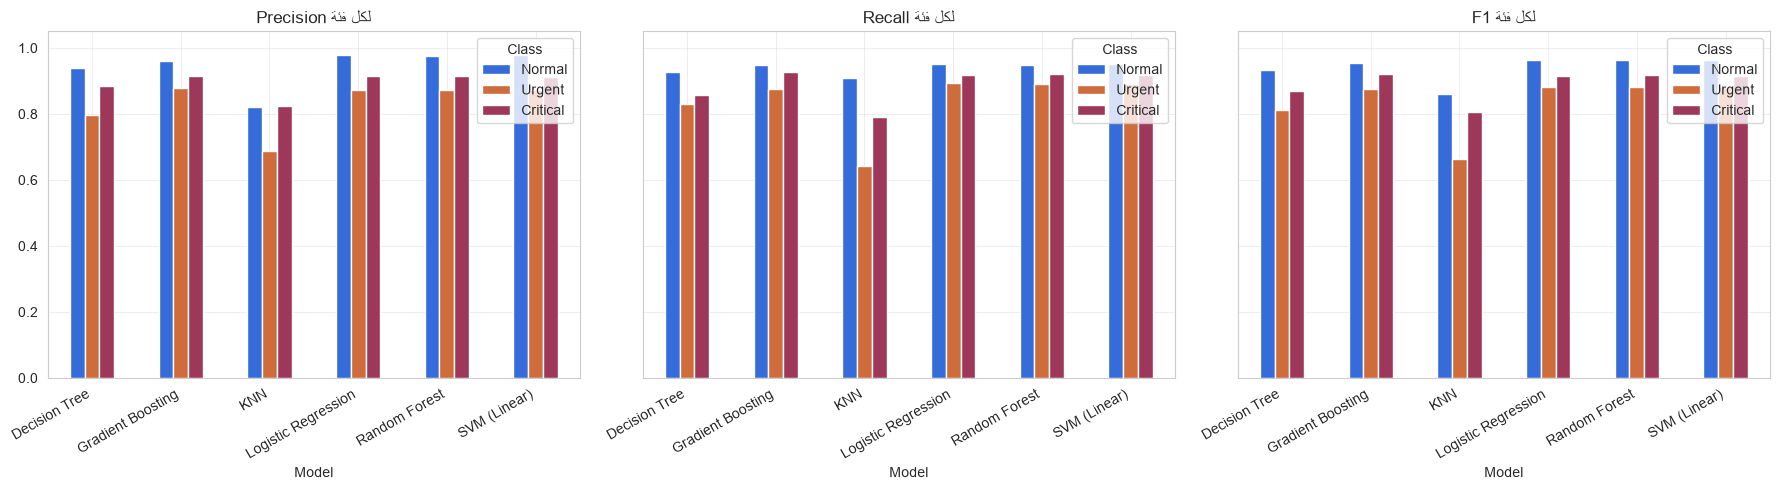

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    pivot = per_class_df.pivot(index="Model", columns="Class", values=metric)[class_order]
    pivot.plot(kind='bar', ax=ax)
    ax.set_title(metric + "  ")
    ax.set_ylim(0, 1.05)
    ax.legend(title="Class")
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

# 7.3)  ROC (One-vs-Rest)
  target  one-vs-rest (    )   ROC   AUC
   .

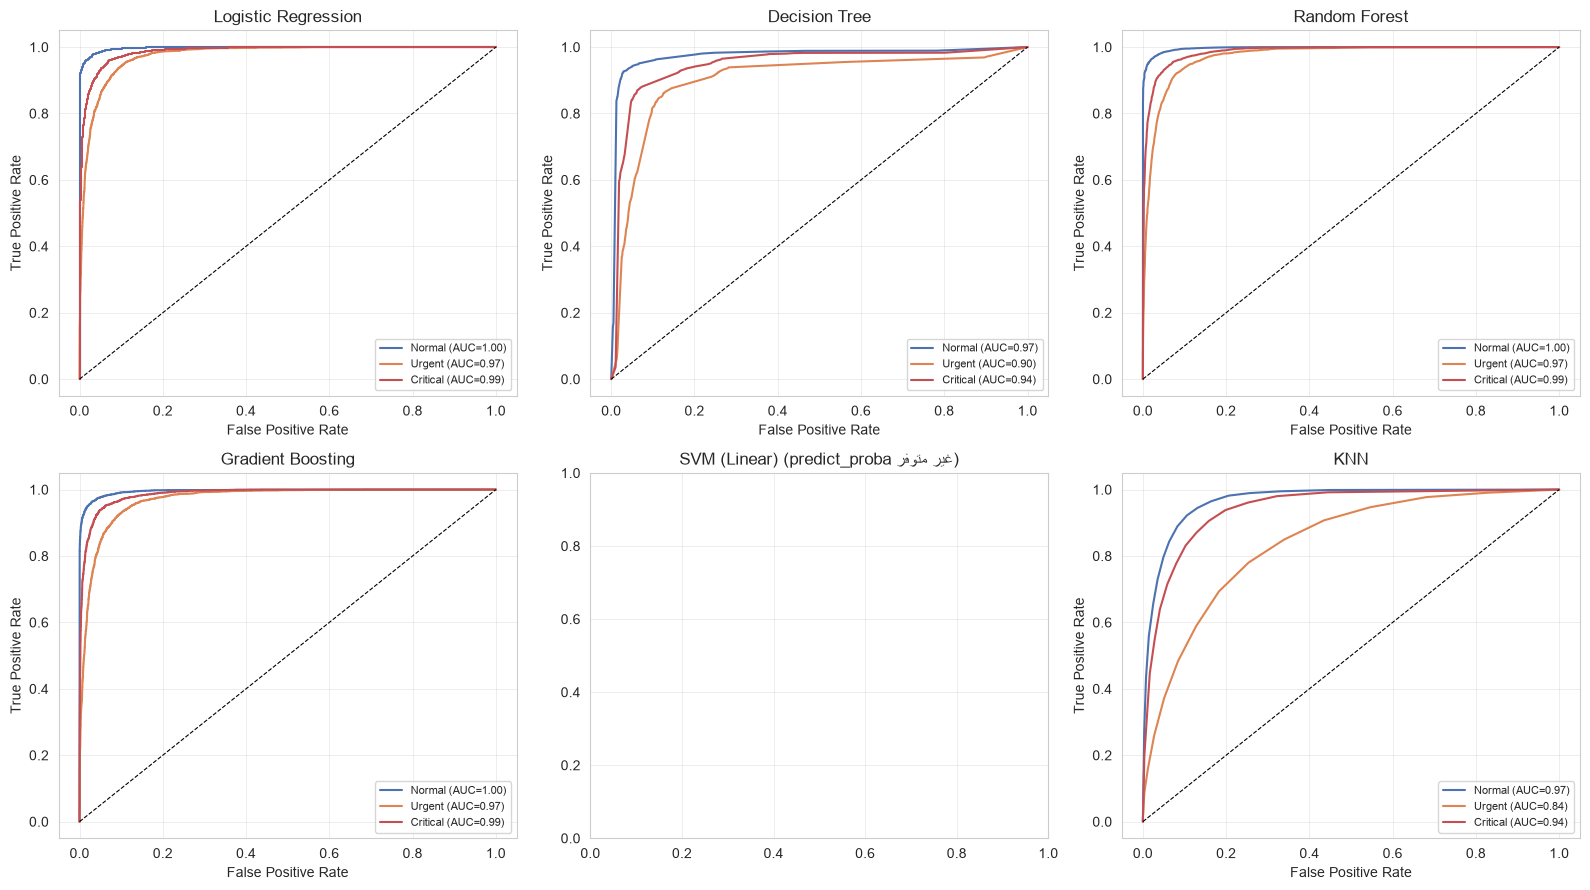

In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3
colors = ['#4C72B0', '#DD8452', '#C44E52']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, pipelines.keys()):
    pipe = trained_pipelines[name]
    if not hasattr(pipe.named_steps['clf'], "predict_proba"):
        ax.set_title(f"{name} (predict_proba  )")
        continue
    y_score = pipe.predict_proba(X_test)
    for i, cls in enumerate(class_order):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=colors[i], label=f"{cls} (AUC={roc_auc:.2f})")
    ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7.4) comparison  (Radar Chart)
    model  4   : Accuracy, Precision, Recall, F1.

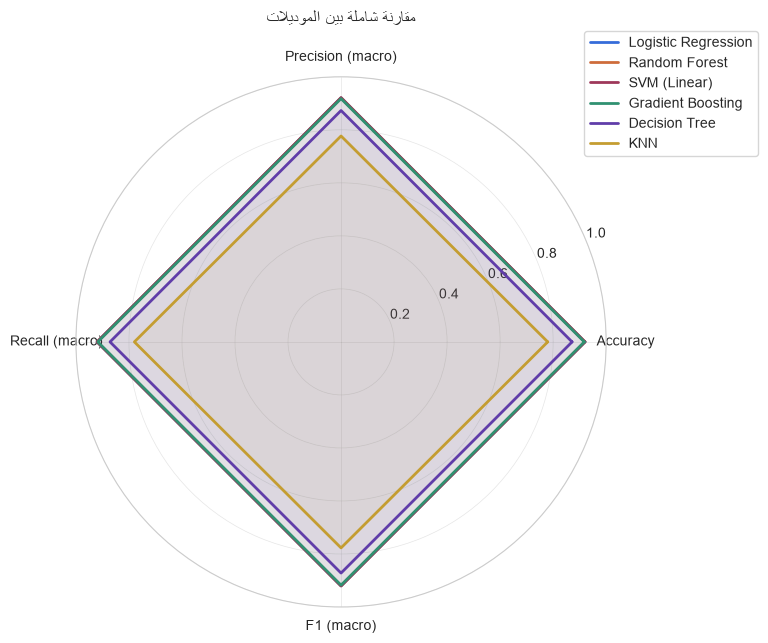

In [15]:
from math import pi

metrics_for_radar = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
n_metrics = len(metrics_for_radar)
angles = [n / float(n_metrics) * 2 * pi for n in range(n_metrics)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for _, row in results_df.iterrows():
    values = [row[m] for m in metrics_for_radar]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=row["Model"])
    ax.fill(angles, values, alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics_for_radar)
ax.set_ylim(0, 1)
ax.set_title("comparison   model", pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# 8)   best model


In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]
best_preds = best_pipe.predict(X_test)

print(f"best model: {best_model_name}\n")
print(classification_report(y_test, best_preds, target_names=class_order))

best model: Logistic Regression

              precision    recall  f1-score   support

      Normal       0.98      0.95      0.96      3875
      Urgent       0.87      0.89      0.88      3875
    Critical       0.91      0.92      0.92      3875

    accuracy                           0.92     11625
   macro avg       0.92      0.92      0.92     11625
weighted avg       0.92      0.92      0.92     11625



# 9)    OneHot + TF-IDF
      ColumnTransformer (    OneHot   TF-IDF).

In [17]:
rf_pipe = trained_pipelines["Random Forest"]
feature_names = rf_pipe.named_steps['preprocess'].get_feature_names_out()
importances = pd.Series(rf_pipe.named_steps['clf'].feature_importances_, index=feature_names)

print(" 20 :")
print(importances.sort_values(ascending=False).head(20))

 20 :
num__spo2            0.089508
num__heart_rate      0.081330
num__resp_rate       0.078155
num__temp            0.063024
num__sys_bp          0.058257
text__moderate       0.041838
text__mild           0.039254
num__dias_bp         0.036961
num__pain_score      0.029736
text__severe         0.022145
num__age             0.020288
text__chest pain     0.010777
text__trauma         0.010604
text__vomiting       0.008511
text__minor          0.008494
text__new onset      0.007128
text__chest          0.006612
text__new            0.006604
text__dehydration    0.005651
text__fever          0.005212
dtype: float64


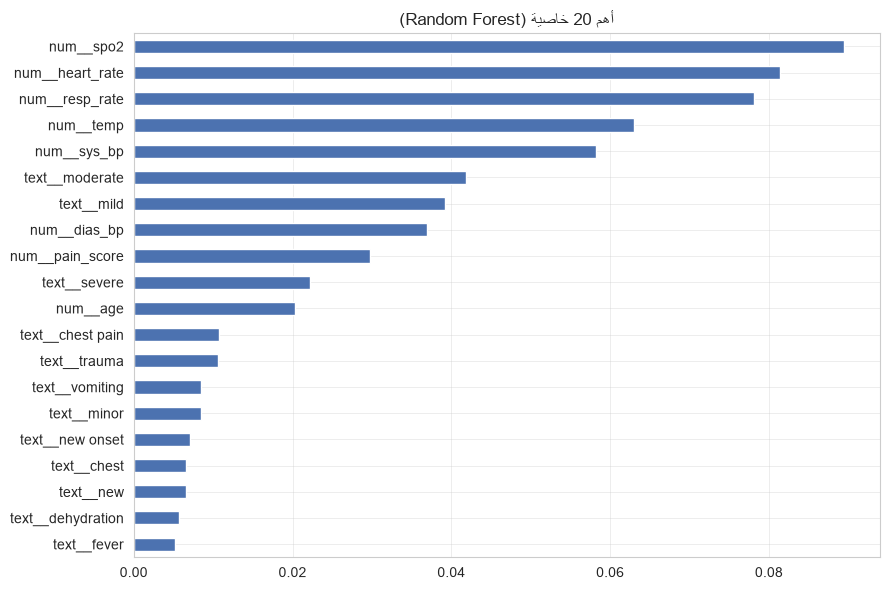

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
importances.sort_values(ascending=True).tail(20).plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title(" 20  (Random Forest)")
plt.tight_layout()
plt.show()

# 10)  model
  Pipeline   prediction   —   DataFrame  columns 
(     Pipeline    ).

In [ ]:
def predict_new_case(patient_dict, model_name=None):
    """
    patient_dict     feature_cols (     target_triage_acuity)
      chief_complaint_text  .
    """
    model_name = model_name or best_model_name
    pipe = trained_pipelines[model_name]

    row = pd.DataFrame([patient_dict])[feature_cols]
    pred = pipe.predict(row)
    pred_proba = pipe.predict_proba(row)
    label = idx_to_class[pred[0]]

    print(" :", label)
    print("Done:", dict(zip(class_order, np.round(pred_proba[0], 3))))
    return label


example_patient = {col: 0 for col in feature_cols}
example_patient.update({
    'chief_complaint_text': 'chest pain, severe, radiating to left arm. shortness of breath, severe',
    'age': 68, 'sex': 'Male', 'ems_arrival': 'Yes', 'temp': 39.2,
    'heart_rate': 138, 'resp_rate': 30, 'sys_bp': 78, 'dias_bp': 48,
    'spo2': 84, 'pain_score': 9, 'seen_last_72h': 1,
    'episode': 'Initial visit to this ED', 'is_injury_poison': 'No injury',
})
predict_new_case(example_patient)

 : Critical
Done: {'Normal': np.float64(0.0), 'Urgent': np.float64(0.039), 'Critical': np.float64(0.961)}


'Critical'

# 11) save  Pipeline ( +   )


In [20]:
import joblib

joblib.dump(trained_pipelines[best_model_name], f"best_pipeline_{best_model_name.replace(' ', '_')}.pkl")
joblib.dump(class_order, "class_order.pkl")

print(f"Done save  Pipeline: {best_model_name}")
print(" : pipe = joblib.load('best_pipeline_...pkl'); pipe.predict(new_dataframe)")

Done save  Pipeline: Logistic Regression
 : pipe = joblib.load('best_pipeline_...pkl'); pipe.predict(new_dataframe)


 ##  results


In [21]:
print(results_df.to_string(index=False))

              Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  CV Accuracy (mean)  CV Accuracy (std)
Logistic Regression  0.920258           0.921229        0.920258    0.920629            0.922816           0.001945
      Random Forest  0.920000           0.920803        0.920000    0.920314            0.921160           0.001599
       SVM (Linear)  0.920000           0.920989        0.920000    0.920378            0.922644           0.001541
  Gradient Boosting  0.917505           0.917634        0.917505    0.917548            0.914342           0.001808
      Decision Tree  0.871484           0.872884        0.871484    0.871993            0.871159           0.001593
                KNN  0.779613           0.776740        0.779613    0.777067            0.774683           0.003484
